# Capital parado no pátio: uma análise de gestão de estoque de uma concessionária

**Autora:** Thamires Martins da Silva
**Fonte dos dados:** Relatório de estoque de uma concessionária de Lucas do Rio Verde (MT), 03/08/2026
**Ferramentas:** Python (pandas, matplotlib)

---

## Contexto

Toda concessionária vive uma tensão: cada veículo parado no pátio é dinheiro imobilizado que não está girando. Um estoque saudável vende rápido; um estoque problemático acumula capital em veículos que ninguém leva. Este projeto mede exatamente isso — **quanto capital está parado, onde, e o que está encalhando** — a partir do relatório de estoque real de uma concessionária.

> **Pergunta de negócio:** Quanto do capital da loja está imobilizado em estoque, qual parcela está parada há tempo demais, e que tipo de veículo trava esse dinheiro?

## Sobre os dados

São **184 veículos** listados no estoque em 03/08/2026, com modelo, tipo, ano, preço anunciado, combustível, câmbio, data de entrada e dias parados. Os dados são reais, mas foram **anonimizados**: nome das lojas substituído por "Loja 1/2/3", e identificadores sensíveis (placa e RENAVAM) removidos por completo. Não há dado de custo, margem ou cliente — apenas o preço de venda anunciado, que é informação pública.

**Limitações assumidas:** (1) é uma fotografia de um único dia, não uma série histórica; (2) o preço é o *anunciado*, não o de venda nem o custo de aquisição; (3) 61 veículos (quase todos motos novas) estão como "Consulte", sem preço — entram nas contagens, mas ficam de fora das análises de valor; (4) não há quilometragem, então a depreciação é analisada por ano, não por km; (5) a análise por loja é limitada, porque a grande maioria do estoque está concentrada numa única loja.

## 1. Configuração e carga

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

AZUL_ESC='#1a3a5c'; AZUL='#2c7fb8'; TEAL='#7fcdbb'; LARANJA='#e8703a'; CINZA='#8a9299'

def reais(v):
    return ('R$ '+format(int(round(v)),',d')).replace(',','.')

df = pd.read_csv(Path.cwd()/'estoque_lucas.csv', sep=';')
print(f'Veiculos no estoque: {len(df)}')
print(f'Com preco anunciado: {df["preco"].notna().sum()}  |  Sem preco (consulte): {df["preco"].isna().sum()}')
print(f'Lojas: {df["loja"].value_counts().to_dict()}')
print()
print(df[['marca','modelo','tipo','ano_modelo','preco','dias','locado','repasse','loja']].head(6).to_string(index=False))

Veiculos no estoque: 184
Com preco anunciado: 123  |  Sem preco (consulte): 61
Lojas: {'Loja 1': 155, 'Loja 2': 23, 'Loja 3': 6}

        marca              modelo  tipo  ano_modelo    preco  dias  locado  repasse   loja
AVELLOZ MOTOS         AVELLOZ 125  moto        2025  11990.0    56   False    False Loja 2
          BMW BMW 43OI GRAN COUPE carro        2017 139990.0   136   False     True Loja 1
        CHERY         TIGGO 7 TXS carro        2021  96990.0    56   False    False Loja 1
    CHEVROLET    BLAZER ADVANTAGE carro        2008  31990.0   255   False     True Loja 2
    CHEVROLET          CAMARO 2SS carro        2013 199990.0   156   False    False Loja 1
    CHEVROLET          CLASSIC LS carro        2015      NaN     7   False    False Loja 1


## 2. O que há no pátio

In [2]:
com_preco = df[df['preco'].notna()].copy()
print('=== VISAO GERAL ===')
print(f'  Total de veiculos:       {len(df)}')
print(f'  Carros:                  {(df["tipo"]=="carro").sum()}')
print(f'  Motos:                   {(df["tipo"]=="moto").sum()}')
print()
print(f'  Valor total em estoque:  {reais(com_preco["preco"].sum())}  (nos {len(com_preco)} com preco)')
print(f'  Ticket medio carro:      {reais(com_preco[com_preco.tipo=="carro"]["preco"].mean())}')
print(f'  Ticket medio moto:       {reais(com_preco[com_preco.tipo=="moto"]["preco"].mean())}')

=== VISAO GERAL ===
  Total de veiculos:       184
  Carros:                  91
  Motos:                   93

  Valor total em estoque:  R$ 8.266.200  (nos 123 com preco)
  Ticket medio carro:      R$ 94.000
  Ticket medio moto:       R$ 15.528


### Leitura

O pátio tem praticamente metade carros, metade motos em número de unidades — mas em dinheiro a história é outra, e é isso que a próxima seção mostra.

## 3. Onde está o dinheiro

In [3]:
valor_tipo = com_preco.groupby('tipo')['preco'].agg(['count','sum'])
print('=== VALOR EM ESTOQUE POR TIPO ===')
for t,r in valor_tipo.iterrows():
    print(f'  {t.capitalize():8} {int(r["count"]):3} veic   {reais(r["sum"]):>16}   ({r["sum"]/com_preco["preco"].sum()*100:.0f}% do capital)')
print()
# faixas de preco
faixas=[0,50000,100000,150000,10**9]
rot=['Ate 50 mil','50-100 mil','100-150 mil','Acima de 150 mil']
com_preco['faixa']=pd.cut(com_preco['preco'],bins=faixas,labels=rot)
print('=== CAPITAL POR FAIXA DE PRECO ===')
for f,s in com_preco.groupby('faixa',observed=True)['preco'].agg(['count','sum']).iterrows():
    print(f'  {f:18} {int(s["count"]):3} veic   {reais(s["sum"]):>16}')

=== VALOR EM ESTOQUE POR TIPO ===
  Carro     81 veic       R$ 7.614.020   (92% do capital)
  Moto      42 veic         R$ 652.180   (8% do capital)

=== CAPITAL POR FAIXA DE PRECO ===
  Ate 50 mil          63 veic       R$ 1.340.880
  50-100 mil          22 veic       R$ 1.587.780
  100-150 mil         32 veic       R$ 3.832.600
  Acima de 150 mil     6 veic       R$ 1.504.940


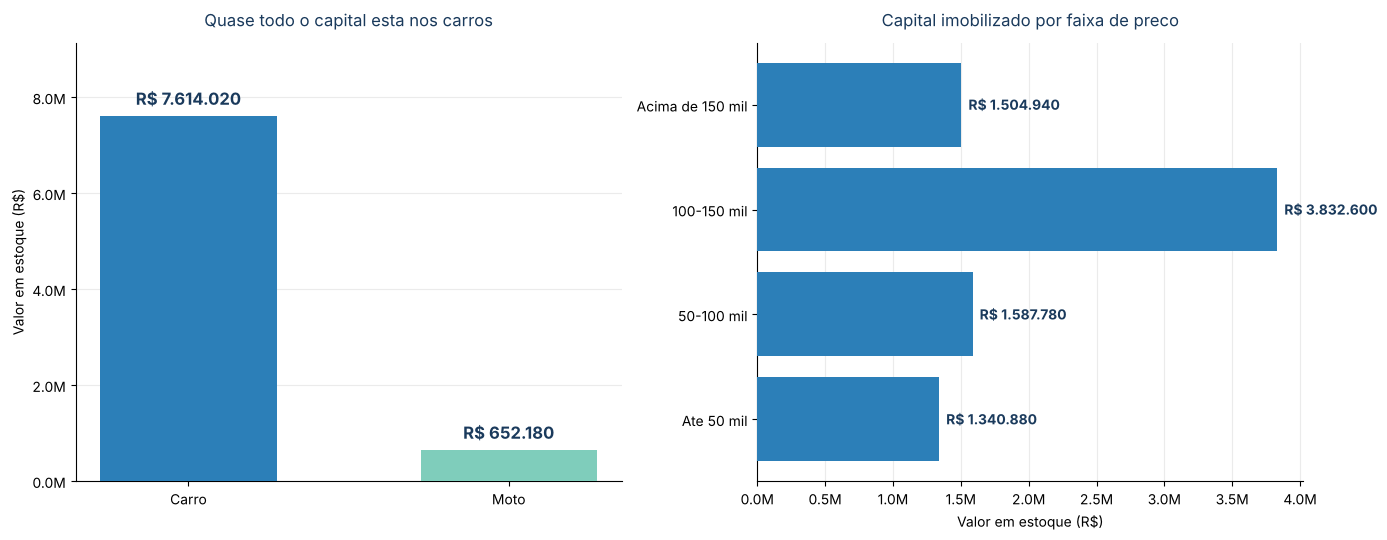

In [4]:
fig,(ax1,ax2)=plt.subplots(1,2,figsize=(14,5.5))
# esq: valor por tipo
vt=valor_tipo['sum']
ax1.bar(['Carro','Moto'],[vt['carro'],vt['moto']],color=[AZUL,TEAL],width=.55,zorder=3)
for x,y in enumerate([vt['carro'],vt['moto']]):
    ax1.annotate(reais(y),(x,y),textcoords='offset points',xytext=(0,8),ha='center',
                 fontsize=12,fontweight='bold',color=AZUL_ESC)
ax1.set_title('Quase todo o capital esta nos carros',fontsize=12,color=AZUL_ESC,pad=12)
ax1.set_ylabel('Valor em estoque (R$)'); ax1.set_ylim(0,vt['carro']*1.2)
ax1.spines['top'].set_visible(False); ax1.spines['right'].set_visible(False)
ax1.grid(True,axis='y',alpha=.25,zorder=0)
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,p:f'{x/1e6:.1f}M'))
# dir: capital por faixa
cf=com_preco.groupby('faixa',observed=True)['preco'].sum().reindex(rot)
ax2.barh(cf.index,cf.values,color=AZUL,zorder=3)
for i,v in enumerate(cf.values):
    ax2.annotate(reais(v),(v,i),textcoords='offset points',xytext=(5,0),va='center',
                 fontsize=10,fontweight='bold',color=AZUL_ESC)
ax2.set_title('Capital imobilizado por faixa de preco',fontsize=12,color=AZUL_ESC,pad=12)
ax2.set_xlabel('Valor em estoque (R$)')
ax2.spines['top'].set_visible(False); ax2.spines['right'].set_visible(False)
ax2.grid(True,axis='x',alpha=.25,zorder=0)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda x,p:f'{x/1e6:.1f}M'))
plt.tight_layout(); plt.show()

### Leitura

Os carros são só metade das unidades, mas concentram **mais de 90% do capital** do estoque — as motos, apesar de numerosas, pesam pouco no dinheiro parado. Para o dono, isso significa uma coisa prática: o problema de capital imobilizado se resolve olhando os carros, não o pátio inteiro.

## 4. Tempo é dinheiro: o capital parado

In [5]:
faixas_dias=[-1,30,90,180,10**9]
rot_d=['0-30 dias','31-90 dias','91-180 dias','Mais de 180 dias']
com_preco['aging']=pd.cut(com_preco['dias'],bins=faixas_dias,labels=rot_d)
ag=com_preco.groupby('aging',observed=True)['preco'].agg(['count','sum']).reindex(rot_d)
print('=== CAPITAL POR TEMPO EM ESTOQUE ===')
tot=com_preco['preco'].sum()
for f,r in ag.iterrows():
    print(f'  {f:18} {int(r["count"]):3} veic   {reais(r["sum"]):>16}   ({r["sum"]/tot*100:.0f}% do capital)')
print()
parado=com_preco[com_preco['dias']>180]
print(f'>>> {len(parado)} veiculos estao parados ha mais de 180 dias,')
print(f'    imobilizando {reais(parado["preco"].sum())} ({parado["preco"].sum()/tot*100:.0f}% do capital do estoque).')

=== CAPITAL POR TEMPO EM ESTOQUE ===
  0-30 dias            3 veic         R$ 179.770   (2% do capital)
  31-90 dias          55 veic       R$ 2.091.250   (25% do capital)
  91-180 dias         31 veic       R$ 2.818.600   (34% do capital)
  Mais de 180 dias    34 veic       R$ 3.176.580   (38% do capital)

>>> 34 veiculos estao parados ha mais de 180 dias,
    imobilizando R$ 3.176.580 (38% do capital do estoque).


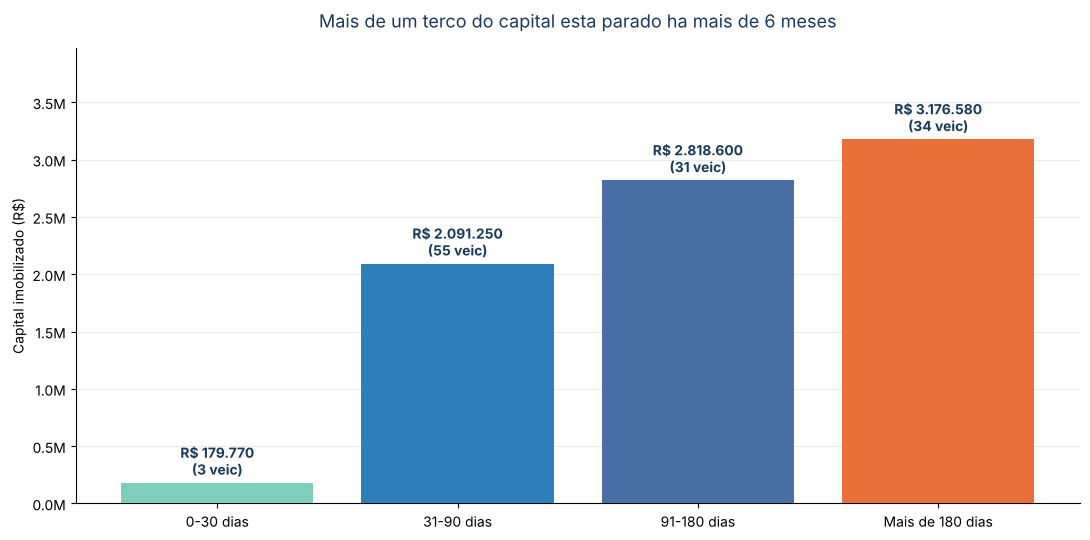

In [6]:
fig,ax=plt.subplots(figsize=(11,5.5))
cores=[TEAL,AZUL,'#4a6fa5',LARANJA]
ax.bar(ag.index,ag['sum'],color=cores,zorder=3)
for i,(v,n) in enumerate(zip(ag['sum'],ag['count'])):
    ax.annotate(f'{reais(v)}\n({int(n)} veic)',(i,v),textcoords='offset points',xytext=(0,6),
                ha='center',fontsize=10,fontweight='bold',color=AZUL_ESC)
ax.set_title('Mais de um terco do capital esta parado ha mais de 6 meses',
             fontsize=13,color=AZUL_ESC,pad=15)
ax.set_ylabel('Capital imobilizado (R$)'); ax.set_ylim(0,ag['sum'].max()*1.25)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True,axis='y',alpha=.25,zorder=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,p:f'{x/1e6:.1f}M'))
plt.tight_layout(); plt.show()

### Leitura

Esse é o número que o dono precisa ver. Boa parte do estoque gira num ritmo saudável — mas **mais de um terço do capital está travado em veículos parados há mais de seis meses**. Esse dinheiro não é abstrato: é caixa que poderia estar comprando veículos que vendem rápido, pagando custos ou rendendo. A próxima seção mostra *quais* veículos são esses.

## 5. Os campeões de encalhe

In [7]:
print('=== 8 VEICULOS MAIS PARADOS ===')
for _,r in com_preco.nlargest(8,'dias').iterrows():
    tag=' [LOCADO]' if r['locado'] else (' [repasse]' if r['repasse'] else '')
    print(f'  {int(r["dias"]):4} dias  {reais(r["preco"]):>12}  {r["marca"]} {r["modelo"]}{tag}')
print()
# locado vs repasse vs normal
def categoria(r):
    if r['locado']: return 'Ex-locado'
    if r['repasse']: return 'Repasse'
    return 'Normal'
com_preco['categoria']=com_preco.apply(categoria,axis=1)
cat=com_preco.groupby('categoria')['dias'].agg(['count','mean','median'])
print('=== TEMPO MEDIO EM ESTOQUE POR ORIGEM ===')
for c,r in cat.iterrows():
    print(f'  {c:10} {int(r["count"]):3} veic   media {r["mean"]:5.0f} dias   mediana {r["median"]:4.0f} dias')
print()
loc=com_preco[com_preco['locado']]
print(f'>>> Os ex-locados ({len(loc)} veiculos) imobilizam {reais(loc["preco"].sum())},')
print(f'    parados em media ha {loc["dias"].mean():.0f} dias -- quase um ano.')

=== 8 VEICULOS MAIS PARADOS ===
   604 dias    R$ 111.990  FIAT STRADA FREEDOM CD [LOCADO]
   601 dias    R$ 129.900  TOYOTA HILUX SW4 4X4 DI
   593 dias    R$ 114.990  CHEVROLET ONIX SEDAN PREMIER AT
   592 dias     R$ 89.990  FIAT ARGO DRIVE COM KIT [LOCADO]
   550 dias    R$ 124.990  FIAT TORO ENDUR T270 AT6 [LOCADO]
   535 dias    R$ 109.990  FIAT CRONOS DRIVE [LOCADO]
   509 dias    R$ 104.990  FIAT CRONOS DRIVE [LOCADO]
   503 dias    R$ 109.990  JEEP RENEGADE LONGITUDE

=== TEMPO MEDIO EM ESTOQUE POR ORIGEM ===
  Ex-locado   15 veic   media   329 dias   mediana  349 dias
  Normal      82 veic   media   148 dias   mediana   78 dias
  Repasse     26 veic   media   153 dias   mediana  113 dias

>>> Os ex-locados (15 veiculos) imobilizam R$ 1.767.850,
    parados em media ha 329 dias -- quase um ano.


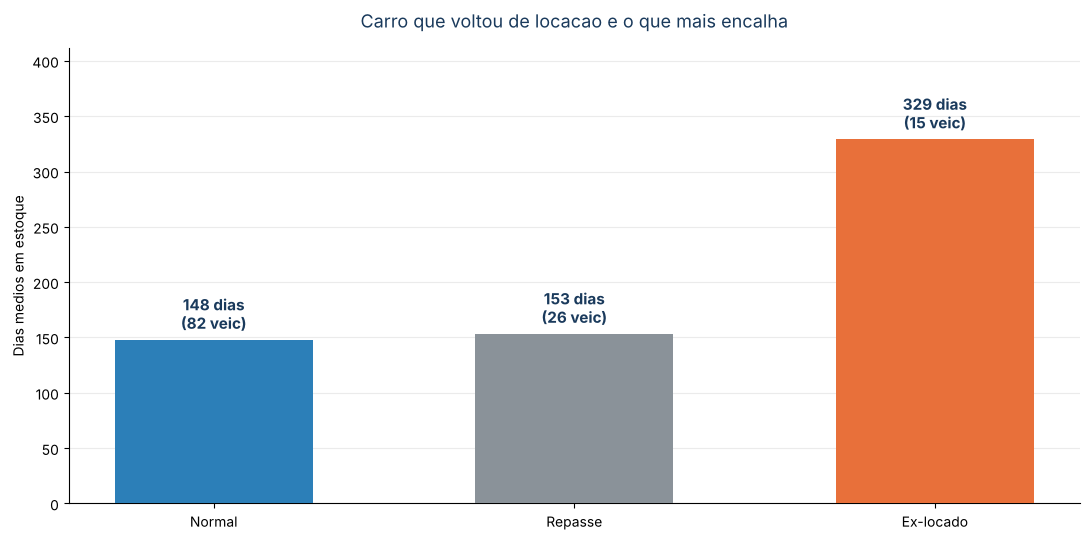

In [8]:
fig,ax=plt.subplots(figsize=(11,5.5))
cat2=cat.reindex(['Normal','Repasse','Ex-locado'])
cores=[AZUL,CINZA,LARANJA]
ax.bar(cat2.index,cat2['mean'],color=cores,width=.55,zorder=3)
for x,(m,n) in enumerate(zip(cat2['mean'],cat2['count'])):
    ax.annotate(f'{m:.0f} dias\n({int(n)} veic)',(x,m),textcoords='offset points',xytext=(0,8),
                ha='center',fontsize=11,fontweight='bold',color=AZUL_ESC)
ax.set_title('Carro que voltou de locacao e o que mais encalha',fontsize=13,color=AZUL_ESC,pad=15)
ax.set_ylabel('Dias medios em estoque'); ax.set_ylim(0,cat2['mean'].max()*1.25)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True,axis='y',alpha=.25,zorder=0)
plt.tight_layout(); plt.show()

### Leitura

Aqui está o diagnóstico fino. O senso comum culparia os carros de repasse, mas os dados dizem o contrário: **repasse gira praticamente no mesmo ritmo que o estoque normal.** O verdadeiro vilão são os **ex-locados** — veículos que voltaram da locação e ficam parados muito mais tempo, quase um ano em média, imobilizando um valor expressivo. É um alvo concreto: uma política específica de precificação e giro para ex-locados resolveria boa parte do capital travado.

## 6. Depreciação: preço por ano do veículo

In [9]:
carros=com_preco[(com_preco.tipo=='carro') & com_preco['ano_modelo'].notna()]
dep=carros.groupby('ano_modelo')['preco'].agg(['count','mean'])
dep=dep[dep['count']>=2]
print('=== PRECO MEDIO DO CARRO POR ANO-MODELO (2+ veiculos) ===')
for a,r in dep.iterrows():
    print(f'  {int(a)}   n={int(r["count"]):2}   {reais(r["mean"]):>14}')

=== PRECO MEDIO DO CARRO POR ANO-MODELO (2+ veiculos) ===
  2010   n= 6        R$ 30.642
  2011   n= 4        R$ 26.490
  2012   n= 3        R$ 76.627
  2013   n= 5        R$ 66.990
  2014   n= 3        R$ 53.990
  2015   n= 2        R$ 74.990
  2016   n= 3        R$ 80.657
  2017   n= 4        R$ 94.240
  2018   n= 4        R$ 91.490
  2019   n= 3        R$ 78.990
  2020   n= 4        R$ 77.240
  2021   n= 3       R$ 138.323
  2022   n= 3        R$ 86.660
  2023   n= 5        R$ 77.390
  2024   n= 5       R$ 181.190
  2025   n=11       R$ 119.626
  2026   n=10       R$ 123.590


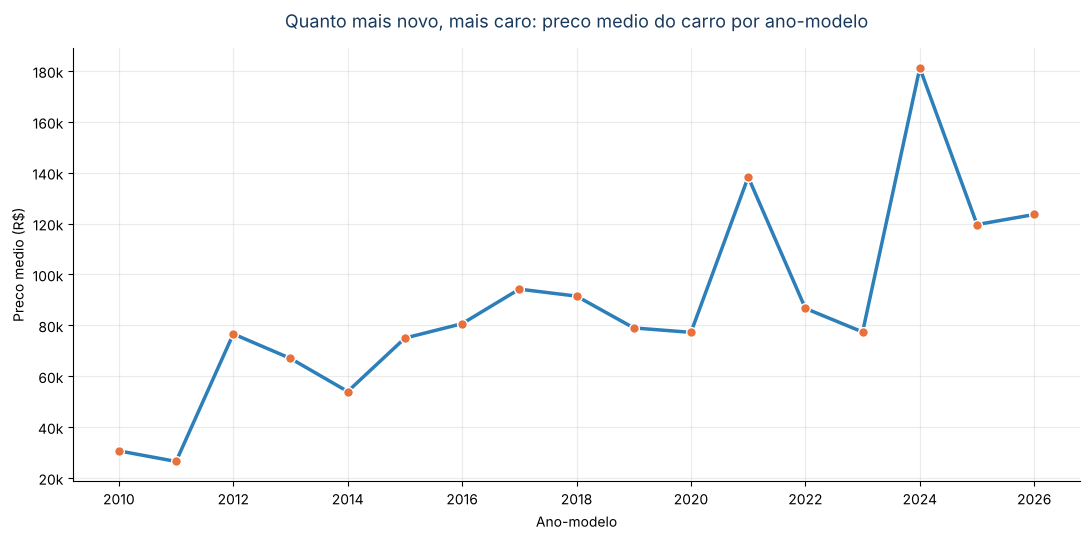

In [10]:
fig,ax=plt.subplots(figsize=(11,5.5))
ax.plot(dep.index,dep['mean'],marker='o',color=AZUL,linewidth=2.5,markersize=7,
        markerfacecolor=LARANJA,markeredgecolor='white',zorder=3)
ax.set_title('Quanto mais novo, mais caro: preco medio do carro por ano-modelo',
             fontsize=13,color=AZUL_ESC,pad=15)
ax.set_xlabel('Ano-modelo'); ax.set_ylabel('Preco medio (R$)')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
ax.grid(True,alpha=.25,zorder=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x,p:f'{x/1000:.0f}k'))
plt.tight_layout(); plt.show()

### Leitura

A curva confirma o esperado — carros mais novos valem mais — mas serve a um propósito prático no estoque: ela dá a referência de quanto cada ano-modelo deveria valer, ajudando a identificar veículos possivelmente *mal precificados* (caros demais para o ano), que são justamente candidatos a encalhar.

## 7. Mix de marcas

In [11]:
mix=com_preco.groupby('marca')['preco'].agg(['count','sum']).sort_values('sum',ascending=False).head(8)
print('=== TOP 8 MARCAS POR CAPITAL EM ESTOQUE ===')
for m,r in mix.iterrows():
    print(f'  {m:14} {int(r["count"]):2} veic   {reais(r["sum"]):>14}')

=== TOP 8 MARCAS POR CAPITAL EM ESTOQUE ===
  FIAT           33 veic     R$ 3.251.670
  CHEVROLET      14 veic     R$ 1.077.860
  TOYOTA          4 veic       R$ 554.790
  VOLKSWAGEN      8 veic       R$ 533.920
  PORSCHE         1 veic       R$ 509.990
  JEEP            5 veic       R$ 474.950
  FORD            6 veic       R$ 427.940
  HONDA MOTOS    16 veic       R$ 304.840


## 8. Limitações

1. **Fotografia de um dia (03/08/2026), não série histórica.** Mostra o estoque num instante; a velocidade de giro ao longo do tempo exigiria vários relatórios.
2. **Preço anunciado, não custo nem venda.** Sem o custo de aquisição não dá para calcular margem; o "capital parado" é medido pelo valor de venda anunciado.
3. **61 veículos sem preço ("Consulte"),** quase todos motos novas — entram nas contagens de unidades, mas ficam fora das análises de valor.
4. **Sem quilometragem.** A depreciação é analisada por ano-modelo, não por km.
5. **Concentração em uma loja.** A maior parte do estoque está na Loja 1, então o corte por loja é apenas indicativo.
6. **Dados anonimizados.** Nomes de loja substituídos por Loja 1/2/3; placa e RENAVAM removidos.

## 9. Síntese executiva

A concessionária tem hoje **R\$ 8,3 milhões imobilizados em estoque**, e quase todo esse capital (mais de 90%) está nos carros — as motos, apesar de metade das unidades, pesam pouco no dinheiro parado.

O ponto que exige ação é o tempo: **mais de um terço do capital — cerca de R\$ 3,2 milhões — está parado há mais de seis meses.** Esse é caixa travado que poderia estar girando.

E o diagnóstico aponta um alvo claro. Ao contrário do que o senso comum sugere, os carros de **repasse giram no ritmo normal** — não são o problema. Os **ex-locados**, sim: veículos que voltaram da locação ficam parados quase um ano em média e concentram boa parte do capital encalhado. Uma política específica de precificação e giro para esse grupo atacaria diretamente a maior fonte de capital imobilizado da loja.

Para o dono, a leitura é direta: o estoque como um todo é saudável, mas há um bolsão de capital preso em veículos caros e antigos de pátio — e ele tem nome. Girar esse bolsão libera caixa sem precisar vender uma unidade sequer a mais do que o normal; basta vender as certas.

---

*Dataset com 184 veículos do estoque de uma concessionária de Lucas do Rio Verde (MT), 03/08/2026, anonimizado. Primeira de uma análise em duas partes: esta mede o capital parado no estoque; a próxima trata da equipe de vendas e do comissionamento.*